# Project 3 — CollegeType
K-Means and Hierarchical Clustering

## 1. Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import linkage, dendrogram

SEED = 42
K_VALUES = range(2, 11)
pd.set_option("display.max_columns", None)

## 2. Load and Prepare Data

In [2]:
# Load dataset
df = pd.read_csv("salaries-by-college-type.csv")
identifier = 'School_Name'
target = 'School_Type'

print(df.shape)
display(df.head())
print("Missing values:")
print(df.isna().sum())

# Select salary features
exclude = [identifier] + ([target] if target is not None else [])
numeric_cols = [c for c in df.columns if c not in exclude]
X = df[numeric_cols].copy()

# Convert salary columns to numeric
for col in numeric_cols:
    X[col] = pd.to_numeric(
        X[col].astype(str)
              .str.replace(r"[$,%]", "", regex=True)
              .str.replace(",", "", regex=False),
        errors="coerce"
    )

# Median imputation
X = X.fillna(X.median())

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Missing after preprocessing:", X.isna().sum().sum())

(269, 8)


,School_Name,School_Type,Starting Median Salary,Mid-Career Median Salary,Mid-Career 10th Percentile Salary,Mid-Career 25th Percentile Salary,Mid-Career 75th Percentile Salary,Mid-Career 90th Percentile Salary
0,Massachusetts Institute of Technology (MIT),Engineering,72200,126000,76800.0,99200,168000,220000.0
1,California Institute of Technology (CIT),Engineering,75500,123000,NaN,104000,161000,NaN
2,Harvey Mudd College,Engineering,71800,122000,NaN,96000,180000,NaN
3,"Polytechnic University of New York, Brooklyn",Engineering,62400,114000,66800.0,94300,143000,190000.0
4,Cooper Union,Engineering,62200,114000,NaN,80200,142000,NaN


Missing values:
School_Name                           0
School_Type                           0
Starting Median Salary                0
Mid-Career Median Salary              0
Mid-Career 10th Percentile Salary    38
Mid-Career 25th Percentile Salary     0
Mid-Career 75th Percentile Salary     0
Mid-Career 90th Percentile Salary    38
dtype: int64
Missing after preprocessing: 0


## 3. K-Means — Round 1: Find the Best K

In [3]:
# Test K = 2 to 10
km_results = []
km_labels = {}

for k in K_VALUES:
    model = KMeans(
        n_clusters=k, init="k-means++", n_init=20,
        max_iter=300, tol=0.0001, algorithm="lloyd",
        random_state=SEED
    )
    labels = model.fit_predict(X_scaled)
    km_labels[k] = labels

    result = {
        "K": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "SSE": model.inertia_,
        "Cluster Size": sorted(pd.Series(labels).value_counts().tolist())
    }
    result["NMI"] = normalized_mutual_info_score(df[target], labels)
    km_results.append(result)

km_round1 = pd.DataFrame(km_results)
display(km_round1.round(4))

best_k_km = int(km_round1.loc[km_round1["Silhouette"].idxmax(), "K"])
print("Best K =", best_k_km)

C:\Users\urang\anaconda3\envs\ds69\lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\urang\anaconda3\envs\ds69\lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\urang\anaconda3\envs\ds69\lib\subprocess.py", line 493, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\urang\anaconda3\envs\ds69\lib\subprocess.py", line 858, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\urang\anaconda3\envs\ds69\lib\subprocess.py", line 1327, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, ar

,K,Silhouette,SSE,Cluster Size,NMI
0,2,0.5180,788.1017,"[67, 202]",0.1572
1,3,0.3795,542.4131,"[28, 118, 123]",0.2017
2,4,0.3510,424.2837,"[22, 47, 84, 116]",0.2203
3,5,0.3594,363.3195,"[9, 15, 45, 84, 116]",0.2469
4,6,0.3091,321.1088,"[9, 15, 27, 45, 78, 95]",0.2230
5,7,0.3197,287.5162,"[2, 9, 13, 25, 45, 77, 98]",0.2211
6,8,0.3247,261.6348,"[3, 9, 13, 14, 24, 30, 75, 101]",0.2666
7,9,0.3171,239.6010,"[2, 5, 7, 11, 14, 27, 30, 77, 96]",0.2676
8,10,0.2796,217.4892,"[2, 5, 7, 10, 11, 13, 29, 53, 65, 74]",0.2562


Best K = 2


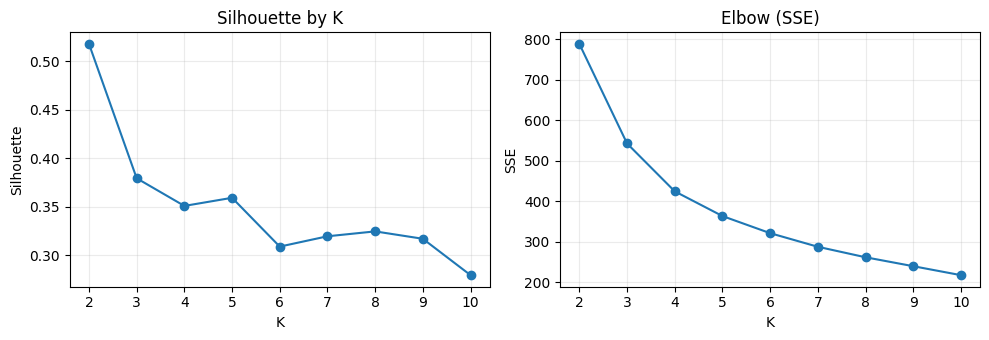

In [4]:
# Silhouette and Elbow plots
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(km_round1["K"], km_round1["Silhouette"], marker="o")
axes[0].set(xlabel="K", ylabel="Silhouette", title="Silhouette by K")
axes[1].plot(km_round1["K"], km_round1["SSE"], marker="o")
axes[1].set(xlabel="K", ylabel="SSE", title="Elbow (SSE)")
for ax in axes:
    ax.set_xticks(list(K_VALUES))
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [5]:
# Check important K candidates
profile_cols = [c for c in [
    "Starting Median Salary",
    "Mid-Career Median Salary",
    "Percent change from Starting to Mid-Career Salary",
    "Mid-Career 90th Percentile Salary"
] if c in X.columns]

for k in [2, 3, 9]:
    check = X.copy()
    check[identifier] = df[identifier]
    check["Cluster"] = km_labels[k]

    print("\nK =", k)
    print("Cluster Size:")
    print(check["Cluster"].value_counts().sort_index())
    print("Cluster Profile:")
    display(check.groupby("Cluster")[profile_cols].mean().round(1))


K = 2
Cluster Size:
Cluster
0     67
1    202
Name: count, dtype: int64
Cluster Profile:


,Starting Median Salary,Mid-Career Median Salary,Mid-Career 90th Percentile Salary
Cluster,,,
0,54428.4,103714.9,190417.9
1,43295.5,77370.8,145970.3



K = 3
Cluster Size:
Cluster
0    123
1     28
2    118
Name: count, dtype: int64
Cluster Profile:


,Starting Median Salary,Mid-Career Median Salary,Mid-Career 90th Percentile Salary
Cluster,,,
0,47177.2,88469.1,163113.8
1,60242.9,112471.4,212357.1
2,41549.2,72431.4,137584.7



K = 9
Cluster Size:
Cluster
0    27
1     7
2    96
3    30
4     2
5    77
6    11
7    14
8     5
Name: count, dtype: int64
Cluster Profile:


,Starting Median Salary,Mid-Career Median Salary,Mid-Career 90th Percentile Salary
Cluster,,,
0,39044.4,63748.1,117963.0
1,56485.7,108428.6,230142.9
2,45178.1,83482.3,158145.8
3,50810.0,95626.7,182000.0
4,73650.0,122500.0,153000.0
5,42281.8,74101.3,140428.6
6,60209.1,108018.2,187909.1
7,50585.7,102892.9,153000.0
8,61580.0,127000.0,295600.0


## 4. K-Means — Round 2: init × n_init

In [6]:
# Test K-Means configurations using the selected K
km_round2_results = []

for init in ["k-means++", "random"]:
    for n_init in [1, 10, 20, 50]:
        model = KMeans(
            n_clusters=best_k_km, init=init, n_init=n_init,
            max_iter=300, tol=0.0001, algorithm="lloyd",
            random_state=SEED
        )
        labels = model.fit_predict(X_scaled)

        result = {
            "init": init,
            "n_init": n_init,
            "Silhouette": silhouette_score(X_scaled, labels),
            "SSE": model.inertia_,
            "Cluster Size": sorted(pd.Series(labels).value_counts().tolist())
        }
        result["NMI"] = normalized_mutual_info_score(df[target], labels)
        km_round2_results.append(result)

km_round2 = pd.DataFrame(km_round2_results)
display(km_round2.round(4))

# Final K-Means configuration
km_final = KMeans(
    n_clusters=best_k_km, init="k-means++", n_init=10,
    max_iter=300, tol=0.0001, algorithm="lloyd",
    random_state=SEED
)
km_final_labels = km_final.fit_predict(X_scaled)
km_final_silhouette = silhouette_score(X_scaled, km_final_labels)
print("Final K-Means Silhouette =", round(km_final_silhouette, 4))
print("Cluster Size:", sorted(pd.Series(km_final_labels).value_counts().tolist()))
print("NMI =", round(normalized_mutual_info_score(df[target], km_final_labels), 4))

,init,n_init,Silhouette,SSE,Cluster Size,NMI
0,k-means++,1,0.518,788.1017,"[67, 202]",0.1572
1,k-means++,10,0.518,788.1017,"[67, 202]",0.1572
2,k-means++,20,0.518,788.1017,"[67, 202]",0.1572
3,k-means++,50,0.518,788.1017,"[67, 202]",0.1572
4,random,1,0.518,788.1017,"[67, 202]",0.1572
5,random,10,0.518,788.1017,"[67, 202]",0.1572
6,random,20,0.518,788.1017,"[67, 202]",0.1572
7,random,50,0.518,788.1017,"[67, 202]",0.1572


Final K-Means Silhouette = 0.518
Cluster Size: [67, 202]
NMI = 0.1572


## 5. Hierarchical — Round 1: Find the Best K

In [7]:
# Ward + Euclidean, K = 2 to 10
h_results = []
h_labels = {}

for k in K_VALUES:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean")
    labels = model.fit_predict(X_scaled)
    h_labels[k] = labels

    result = {
        "K": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Cluster Size": sorted(pd.Series(labels).value_counts().tolist())
    }
    result["NMI"] = normalized_mutual_info_score(df[target], labels)
    h_results.append(result)

h_round1 = pd.DataFrame(h_results)
display(h_round1.round(4))

best_k_h = int(h_round1.loc[h_round1["Silhouette"].idxmax(), "K"])
print("Best K =", best_k_h)

,K,Silhouette,Cluster Size,NMI
0,2,0.6109,"[24, 245]",0.2489
1,3,0.3716,"[24, 110, 135]",0.2043
2,4,0.3201,"[24, 39, 96, 110]",0.1871
3,5,0.3274,"[6, 18, 39, 96, 110]",0.1985
4,6,0.2617,"[6, 18, 39, 46, 64, 96]",0.1941
5,7,0.2700,"[2, 6, 16, 39, 46, 64, 96]",0.1960
6,8,0.2777,"[2, 6, 13, 16, 26, 46, 64, 96]",0.2410
7,9,0.2700,"[2, 6, 8, 13, 16, 26, 38, 64, 96]",0.2353
8,10,0.2690,"[2, 6, 7, 8, 9, 13, 26, 38, 64, 96]",0.2440


Best K = 2


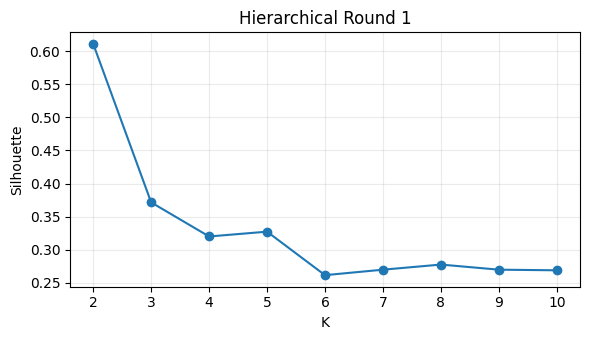

In [8]:
# Silhouette plot
plt.figure(figsize=(6, 3.5))
plt.plot(h_round1["K"], h_round1["Silhouette"], marker="o")
plt.xticks(list(K_VALUES))
plt.xlabel("K")
plt.ylabel("Silhouette")
plt.title("Hierarchical Round 1")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Hierarchical — Round 2: linkage × metric

In [9]:
# Test linkage and metric configurations
configs = [("ward", "euclidean")]
for link in ["complete", "average", "single"]:
    for metric in ["euclidean", "manhattan", "cosine"]:
        configs.append((link, metric))

h_round2_results = []
h_round2_labels = {}

for link, metric in configs:
    model = AgglomerativeClustering(
        n_clusters=best_k_h, linkage=link, metric=metric
    )
    labels = model.fit_predict(X_scaled)
    h_round2_labels[(link, metric)] = labels

    result = {
        "linkage": link,
        "metric": metric,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Cluster Size": sorted(pd.Series(labels).value_counts().tolist())
    }
    result["NMI"] = normalized_mutual_info_score(df[target], labels)
    h_round2_results.append(result)

h_round2 = pd.DataFrame(h_round2_results)
display(h_round2.round(4))

,linkage,metric,Silhouette,Cluster Size,NMI
0,ward,euclidean,0.6109,"[24, 245]",0.2489
1,complete,euclidean,0.5101,"[70, 199]",0.1739
2,complete,manhattan,0.5218,"[54, 215]",0.1568
3,complete,cosine,0.3605,"[104, 165]",0.1096
4,average,euclidean,0.6109,"[24, 245]",0.2489
5,average,manhattan,0.6109,"[24, 245]",0.2489
6,average,cosine,0.4002,"[111, 158]",0.1263
7,single,euclidean,0.5761,"[2, 267]",0.0361
8,single,manhattan,0.6182,"[2, 267]",0.0325
9,single,cosine,-0.2497,"[1, 268]",0.0119


In [10]:
# Final Hierarchical configuration
final_linkage = 'ward'
final_metric = 'euclidean'
h_final_labels = h_round2_labels[(final_linkage, final_metric)]
h_final_silhouette = silhouette_score(X_scaled, h_final_labels)

print("Final Hierarchical:", final_linkage, "+", final_metric)
print("Silhouette =", round(h_final_silhouette, 4))
print("Cluster Size:", sorted(pd.Series(h_final_labels).value_counts().tolist()))
print("NMI =", round(normalized_mutual_info_score(df[target], h_final_labels), 4))

Final Hierarchical: ward + euclidean
Silhouette = 0.6109
Cluster Size: [24, 245]
NMI = 0.2489


## 7. Dendrogram Check

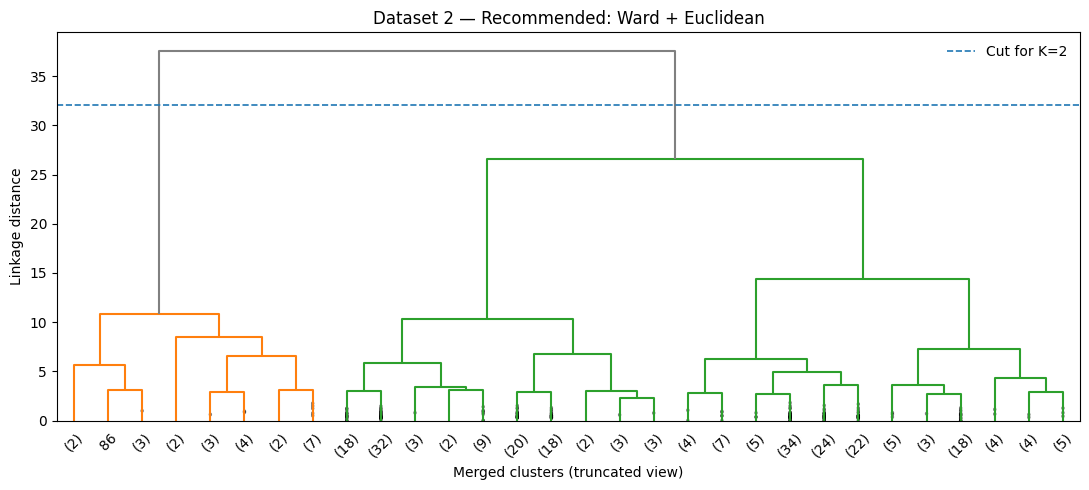

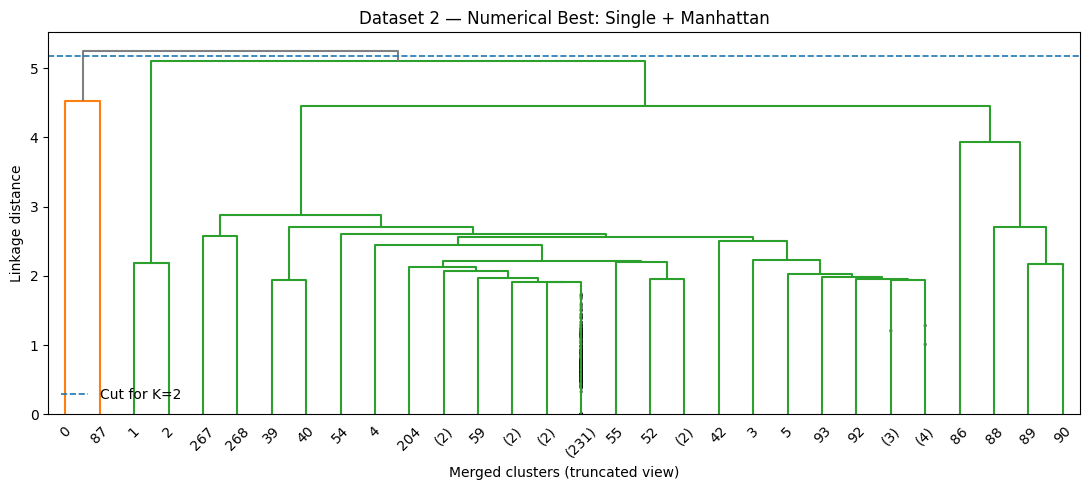

In [11]:
# Recommended: Ward + Euclidean
Z = linkage(X_scaled, method='ward', metric='euclidean')
cut_height = (Z[-best_k_h, 2] + Z[-(best_k_h - 1), 2]) / 2

plt.figure(figsize=(11, 5))
dendrogram(
    Z, truncate_mode="lastp", p=min(30, len(X_scaled)),
    show_contracted=True, color_threshold=cut_height,
    above_threshold_color="grey"
)
plt.axhline(cut_height, linestyle="--", linewidth=1.2, label=f"Cut for K={best_k_h}")
plt.title("Dataset 2 — Recommended: Ward + Euclidean")
plt.xlabel("Merged clusters (truncated view)")
plt.ylabel("Linkage distance")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

# Numerical Best: Single + Manhattan
Z = linkage(X_scaled, method='single', metric='cityblock')
cut_height = (Z[-best_k_h, 2] + Z[-(best_k_h - 1), 2]) / 2

plt.figure(figsize=(11, 5))
dendrogram(
    Z, truncate_mode="lastp", p=min(30, len(X_scaled)),
    show_contracted=True, color_threshold=cut_height,
    above_threshold_color="grey"
)
plt.axhline(cut_height, linestyle="--", linewidth=1.2, label=f"Cut for K={best_k_h}")
plt.title("Dataset 2 — Numerical Best: Single + Manhattan")
plt.xlabel("Merged clusters (truncated view)")
plt.ylabel("Linkage distance")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Final Comparison and Cluster Profile

In [12]:
# Compare final K-Means and Hierarchical models
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical"],
    "Silhouette": [km_final_silhouette, h_final_silhouette],
    "Cluster Size": [
        sorted(pd.Series(km_final_labels).value_counts().tolist()),
        sorted(pd.Series(h_final_labels).value_counts().tolist())
    ]
})
comparison["NMI"] = [
    normalized_mutual_info_score(df[target], km_final_labels),
    normalized_mutual_info_score(df[target], h_final_labels)
]
display(comparison.round(4))

# Final Hierarchical cluster size and profile
final_df = X.copy()
final_df[identifier] = df[identifier]
final_df[target] = df[target]
final_df["Cluster"] = h_final_labels

print("Cluster Size:")
print(final_df["Cluster"].value_counts().sort_index())

print("Cluster Profile:")
display(final_df.groupby("Cluster")[profile_cols].mean().round(1))
print("Ground Truth Distribution:")
display(pd.crosstab(final_df["Cluster"], final_df[target]))
print("Members in each cluster:")
for cluster in sorted(final_df["Cluster"].unique()):
    members = final_df.loc[final_df["Cluster"] == cluster, identifier].tolist()
    print(f"Cluster {cluster} (n={len(members)}):")
    print(", ".join(map(str, members)))

,Algorithm,Silhouette,Cluster Size,NMI
0,K-Means,0.5180,"[67, 202]",0.1572
1,Hierarchical,0.6109,"[24, 245]",0.2489


Cluster Size:
Cluster
0    245
1     24
Name: count, dtype: int64
Cluster Profile:


,Starting Median Salary,Mid-Career Median Salary,Mid-Career 90th Percentile Salary
Cluster,,,
0,44621.2,81035.1,151008.2
1,60841.7,113508.3,218625.0


Ground Truth Distribution:


School_Type,Engineering,Ivy League,Liberal Arts,Party,State
Cluster,,,,,
0,8,0,44,20,173
1,11,8,3,0,2


Members in each cluster:
Cluster 0 (n=245):
Cooper Union, Illinois Institute of Technology (IIT), Wentworth Institute of Technology, Virginia Polytechnic Institute and State University (Virginia Tech), New Mexico Institute of Mining and Technology (New Mexico Tech), Rochester Institute of Technology (RIT), Embry-Riddle Aeronautical University (ERAU), Tennessee Technological University, University of Illinois at Urbana-Champaign (UIUC), University of Maryland, College Park, University of California, Santa Barbara (UCSB), University of Texas (UT) - Austin, State University of New York (SUNY) at Albany, University of Florida (UF), Louisiana State University (LSU), University of Georgia (UGA), Pennsylvania State University (PSU), Arizona State University (ASU), Indiana University (IU), Bloomington, University of Iowa (UI), Randolph-Macon College, University of Alabama, Tuscaloosa, University of Mississippi, University of New Hampshire (UNH), West Virginia University (WVU), University of Te

## 9. Final Cluster Profile Chart

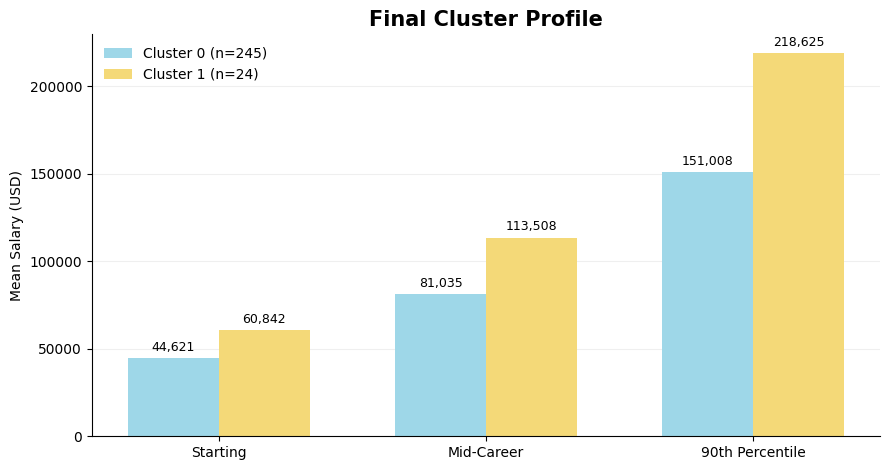

In [13]:
# Final Cluster Profile bar chart
chart_features = [c for c in [
    "Starting Median Salary",
    "Mid-Career Median Salary",
    "Mid-Career 90th Percentile Salary"
] if c in final_df.columns]

profile_chart = final_df.groupby("Cluster")[chart_features].mean()
cluster_order = profile_chart["Mid-Career Median Salary"].sort_values().index.tolist()
profile_chart = profile_chart.loc[cluster_order]

SLIDE_BLUE = "#9ED7E8"
SLIDE_YELLOW = "#F4D978"
colors = [SLIDE_BLUE, SLIDE_YELLOW]

short_names = {
    "Starting Median Salary": "Starting",
    "Mid-Career Median Salary": "Mid-Career",
    "Mid-Career 90th Percentile Salary": "90th Percentile"
}

x = range(len(chart_features))
width = 0.34
fig, ax = plt.subplots(figsize=(9, 4.8))

for i, cluster in enumerate(cluster_order):
    offset = (i - (len(cluster_order) - 1) / 2) * width
    values = profile_chart.loc[cluster].values
    n = int((final_df["Cluster"] == cluster).sum())
    bars = ax.bar(
        [v + offset for v in x], values, width,
        label=f"Cluster {cluster} (n={n})",
        color=colors[i % len(colors)]
    )
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in values], padding=3, fontsize=9)

ax.set_title("Final Cluster Profile", fontsize=15, weight="bold")
ax.set_ylabel("Mean Salary (USD)")
ax.set_xticks(list(x))
ax.set_xticklabels([short_names[c] for c in chart_features])
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.20)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()